# Tarea 28: PDA

## Carga de librerias y lectura de datos

In [1]:
# Libraries for data 
import pandas as pd
import numpy as np
from numpy import linalg as la

# Libraries for plotting
import matplotlib.pyplot as plt

# Libraries for preprocessing and modeling 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load iris csv
iris_df = pd.read_csv('iris.csv') # Load the data

## Proceso de estandarizacion de variables 


In [23]:
# Encoding 'variety' column to numerical values
#iris_df['variety'] = iris_df['variety'].astype('category').cat.codes

# Standarize the whole data
X = iris_df.iloc[:, 0:4].values
df_standarized = StandardScaler().fit_transform(X)

In [32]:
pca = PCA()
model_pca = pca.fit_transform(df_standarized)


print('Eigenvalues: ')
results = pca.explained_variance_
print(results)
print('Explained variance ratio: ')
print(pca.explained_variance_ratio_)

Eigenvalues: 
[2.93808505 0.9201649  0.14774182 0.02085386]
Explained variance ratio: 
[0.72962445 0.22850762 0.03668922 0.00517871]


### Explicación de la razón de varianza

Loa valores en términos del porcentaje, para cada componente:
PC1 = 72.96% 
PC2 = 22.85% 
PC3 =  3.66% 
PC4 =  0.51%

Los dos primeros componentes explican aproximadamente el 95.81 % de la varianza total.

El PC1 solo ya captura casi 73 %, lo que indica una dirección dominante muy clara en los datos.

El PC2 añade ~22.85 %, complementando la estructura principal.

Los componentes 3 y 4 aportan en conjunto solo ~4.19 %, por lo que probablemente representan ruido o variaciones menores.

### Calculo del eigenvector

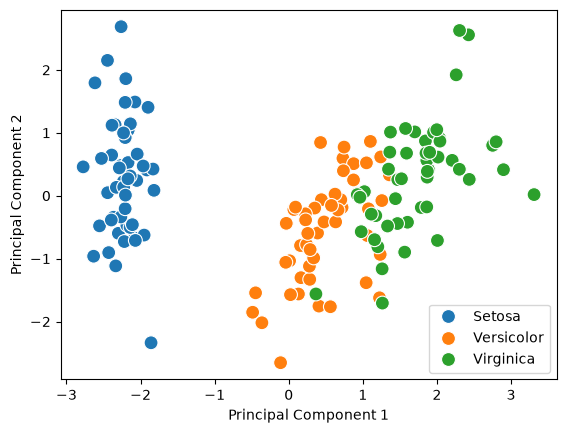

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

pca_df = pd.DataFrame(data=model_pca, columns=['PC1', 'PC2', 'PC3', 'PC4'])
pca_df['variety'] = iris_df.variety

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='variety', s=100)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

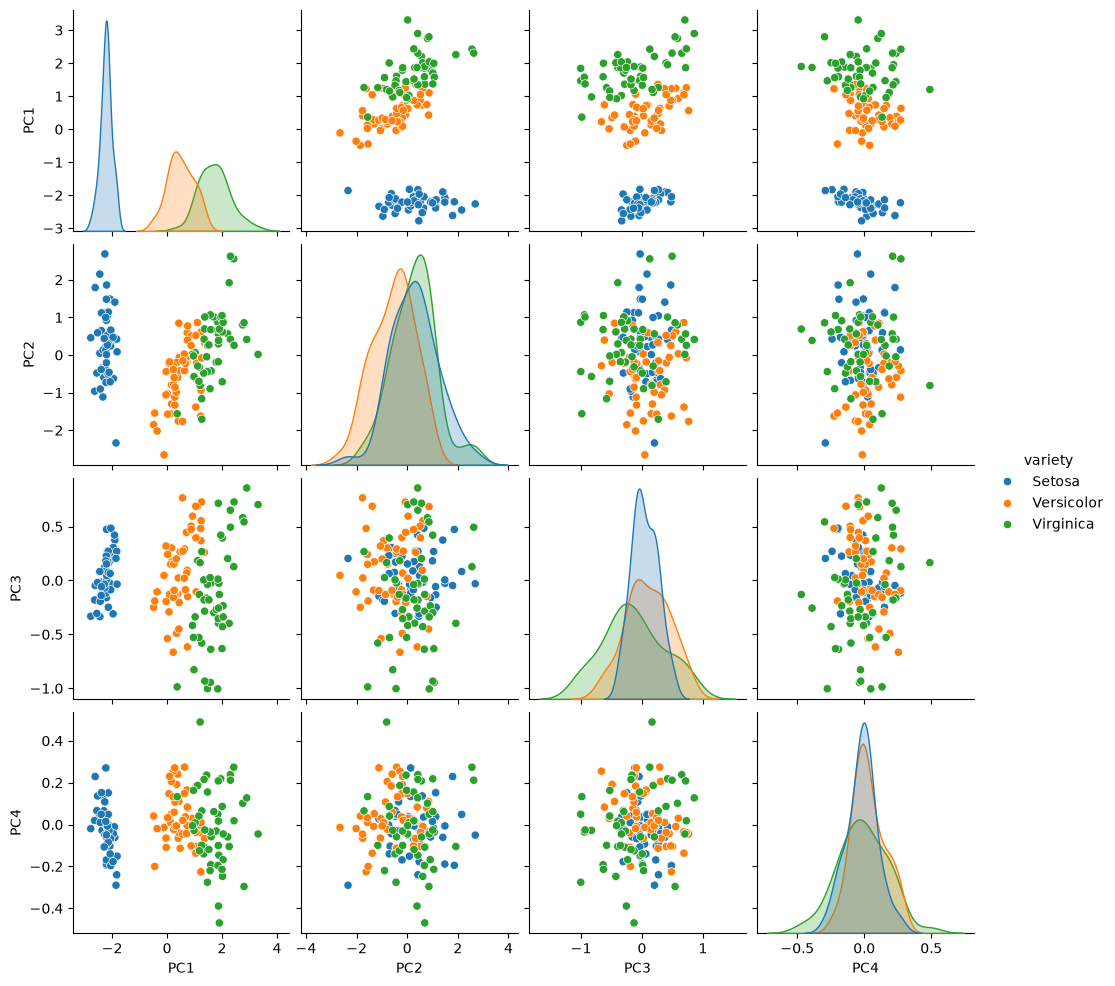

In [31]:
sns.pairplot(pca_df, hue='variety')

Patrón que se observa en las gráficas:
- Separación de setosa (muy clara)

Setosa aparece claramente separada del resto, formando un grupo compacto a un lado (típicamente a la izquierda de PC1, con valores negativos de PC1).

Esto se debe a que setosa tiene pétalos mucho más pequeños → se distingue por el tamaño del pétalo (PC1).

- Versicolor y virginica parcialmente solapadas

Versicolor y virginica se separan mejor a lo largo de PC2 (y también algo en PC1), pero se solapan parcialmente.

Virginica tiende a tener sépalos más anchos y pétalos más grandes → valores más altos en PC2 (y algo en PC1).

La frontera entre ambas no es perfecta en 2D: hay flores de ambas especies mezcladas en la zona central.